# MedTwin AI — Phase 1: Brain MRI/CT Data Exploration

**Project:** MedTwin AI — AI-Based Multi-Disease Brain MRI 3D Reconstruction and Volumetry

**Phase 1 objective:** Load, inspect, validate, lightly preprocess, and visualize **real** brain MRI/CT
data so we understand the dataset before starting brain segmentation in Phase 2.

This notebook does **not**:
- train any deep-learning model
- run automatic segmentation
- build a 3D mesh / digital twin
- build a web application
- implement disease classification

It only works with volumetric medical images (NIfTI / DICOM) — never treats a 3D scan as an ordinary 2D image dataset.

> Run the cells in order, from top to bottom. Cells are organized into clearly labeled sections.


## 1. Environment Check

We check which packages are available. Core packages (NumPy, Matplotlib, NiBabel) are required for
this notebook. Optional packages (SimpleITK, PyTorch, MONAI) are used only if present — they are
**not required** for Phase 1 and are **not installed automatically**.

If a package is reported as `Missing`, install it yourself, e.g.:

```bash
pip install nibabel SimpleITK numpy matplotlib pandas
# Optional, only needed for later phases:
pip install torch monai
```


In [1]:
# ============================================================
# MEDTWIN AI — PHASE 1
# ENVIRONMENT CHECK

# ============================================================

import sys
import importlib
from importlib.metadata import version as pkg_version, PackageNotFoundError


# ------------------------------------------------------------
# 1. Package configuration
# ------------------------------------------------------------

packages_to_check = [
    # Required for Phase 1
    ("NumPy", "numpy", True),
    ("Matplotlib", "matplotlib", True),
    ("NiBabel", "nibabel", True),

    # Recommended / optional
    ("SimpleITK", "SimpleITK", False),
    ("Pandas", "pandas", False),
    ("SciPy", "scipy", False),

    # Required only for later AI phases
    ("PyTorch", "torch", False),
    ("Torchvision", "torchvision", False),
    ("MONAI", "monai", False),

    # Notebook support
    ("ipywidgets", "ipywidgets", False),
]


# ------------------------------------------------------------
# 2. Safe package checker
# ------------------------------------------------------------

def safe_import_package(display_name, import_name, required=False):

    try:

        # Try importing package
        module = importlib.import_module(import_name)

        # Try to obtain installed version
        try:
            package_version = pkg_version(import_name)

        except PackageNotFoundError:
            package_version = getattr(
                module,
                "__version__",
                "unknown"
            )

        return {
            "name": display_name,
            "import_name": import_name,
            "version": str(package_version),
            "status": "Available",
            "required": required,
            "error": None
        }

    except Exception as e:

        # IMPORTANT:
        # Catch ALL exceptions including:
        # OSError
        # ImportError
        # DLL errors
        # ModuleNotFoundError
        # etc.

        return {
            "name": display_name,
            "import_name": import_name,
            "version": "-",
            "status": "Unavailable",
            "required": required,
            "error": f"{type(e).__name__}: {str(e)}"
        }


# ------------------------------------------------------------
# 3. Run environment check
# ------------------------------------------------------------

def check_environment():

    results = []

    print("=" * 78)
    print("MEDTWIN AI — PHASE 1 ENVIRONMENT CHECK")
    print("=" * 78)

    print(f"Python Version : {sys.version.split()[0]}")
    print(f"Python Path    : {sys.executable}")

    print("=" * 78)
    print(
        f"{'Package':<18}"
        f"{'Version':<18}"
        f"{'Status':<18}"
        f"{'Required':<12}"
    )

    print("-" * 78)

    # Check every package safely
    for display_name, import_name, required in packages_to_check:

        result = safe_import_package(
            display_name,
            import_name,
            required
        )

        results.append(result)

        if result["status"] == "Available":

            print(
                f"{display_name:<18}"
                f"{result['version']:<18}"
                f"{'✓ Available':<18}"
                f"{'YES' if required else 'NO':<12}"
            )

        else:

            print(
                f"{display_name:<18}"
                f"{'-':<18}"
                f"{'⚠ Unavailable':<18}"
                f"{'YES' if required else 'NO':<12}"
            )

    print("=" * 78)


    # --------------------------------------------------------
    # 4. Required package analysis
    # --------------------------------------------------------

    required_failed = [
        result
        for result in results
        if result["required"]
        and result["status"] != "Available"
    ]


    optional_failed = [
        result
        for result in results
        if not result["required"]
        and result["status"] != "Available"
    ]


    # --------------------------------------------------------
    # 5. Required package result
    # --------------------------------------------------------

    if len(required_failed) == 0:

        print("\n✅ PHASE 1 REQUIRED PACKAGES ARE AVAILABLE.")

    else:

        print("\n❌ REQUIRED PACKAGE PROBLEMS FOUND:")

        for result in required_failed:

            print(
                f"\n{result['name']}"
            )

            print(
                f"Error: {result['error']}"
            )

        print(
            "\nInstall the missing required packages before continuing."
        )


    # --------------------------------------------------------
    # 6. Optional package result
    # --------------------------------------------------------

    if len(optional_failed) > 0:

        print("\n⚠ OPTIONAL PACKAGE PROBLEMS:")

        for result in optional_failed:

            print(
                f"\n{result['name']}"
            )

            print(
                f"Error: {result['error']}"
            )

        print(
            "\nThese packages are not required for the current "
            "Phase 1 data exploration."
        )


    # --------------------------------------------------------
    # 7. Special PyTorch message
    # --------------------------------------------------------

    torch_result = next(
        (
            result
            for result in results
            if result["import_name"] == "torch"
        ),
        None
    )


    if torch_result is not None:

        if torch_result["status"] == "Unavailable":

            print("\n" + "=" * 78)
            print("PYTORCH STATUS")
            print("=" * 78)

            print("⚠ PyTorch could not be imported.")

            print(
                "\nDetected error:"
            )

            print(
                torch_result["error"]
            )

            print(
                "\nThis does NOT stop Phase 1."
            )

            print(
                "PyTorch will be required later for the "
                "3D segmentation model."
            )

            print(
                "\nFor now, continue with:"
            )

            print("  1. MRI loading")
            print("  2. NIfTI inspection")
            print("  3. MRI visualization")
            print("  4. Segmentation-mask visualization")
            print("  5. Voxel spacing")
            print("  6. Tumor volume calculation")

            print("=" * 78)


    # --------------------------------------------------------
    # 8. Final status
    # --------------------------------------------------------

    if len(required_failed) == 0:

        print("\n" + "=" * 78)
        print("✅ ENVIRONMENT CHECK PASSED FOR PHASE 1")
        print("=" * 78)

        print(
            "\nYou can continue with the BraTS-GLI dataset."
        )

    else:

        print("\n" + "=" * 78)
        print("❌ ENVIRONMENT CHECK FAILED FOR PHASE 1")
        print("=" * 78)

        print(
            "\nFix the required packages before continuing."
        )

    print()

    return results


# ------------------------------------------------------------
# 9. Execute
# ------------------------------------------------------------

env_report = check_environment()

MEDTWIN AI — PHASE 1 ENVIRONMENT CHECK
Python Version : 3.11.15
Python Path    : C:\Users\shshi\anaconda3\envs\Med_twin\python.exe
Package           Version           Status            Required    
------------------------------------------------------------------------------
NumPy             -                 ⚠ Unavailable     YES         
Matplotlib        -                 ⚠ Unavailable     YES         
NiBabel           -                 ⚠ Unavailable     YES         
SimpleITK         -                 ⚠ Unavailable     NO          
Pandas            -                 ⚠ Unavailable     NO          
SciPy             -                 ⚠ Unavailable     NO          
PyTorch           -                 ⚠ Unavailable     NO          
Torchvision       -                 ⚠ Unavailable     NO          
MONAI             -                 ⚠ Unavailable     NO          
ipywidgets        -                 ⚠ Unavailable     NO          

❌ REQUIRED PACKAGE PROBLEMS FOUND:

NumPy
Error: Mod

## 2. Project Path Configuration

Only edit the values in the cell below. Everything else in the notebook derives from these two paths.

- `DATA_DIR`: where your raw MRI/CT dataset lives (NIfTI and/or DICOM files).
- `OUTPUT_DIR`: where this notebook will write exploration reports.

Paths are handled with `pathlib.Path` so this works the same way on Windows, macOS, and Linux.


In [2]:
from pathlib import Path

# ----- EDIT ONLY THESE TWO LINES -----
DATA_DIR = Path(r"C:\Users\admin\Desktop\Med_Twin\Dataset\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData")
OUTPUT_DIR = Path(r"C:\Users\admin\Desktop\Med_Twin\outputs")
# --------------------------------------

DATA_DIR = DATA_DIR.expanduser().resolve()
OUTPUT_DIR = OUTPUT_DIR.expanduser().resolve()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"DATA_DIR   = {DATA_DIR}")
print(f"OUTPUT_DIR = {OUTPUT_DIR}")

if not DATA_DIR.exists():
    print(
        f"\nWARNING: DATA_DIR does not exist yet: {DATA_DIR}\n"
        "Create this folder and place your dataset inside it before continuing."
    )
else:
    print("\n✅ DATA_DIR exists.")

print("✅ OUTPUT_DIR ready.")

DATA_DIR   = C:\Users\admin\Desktop\Med_Twin\Dataset\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData
OUTPUT_DIR = C:\Users\admin\Desktop\Med_Twin\outputs

✅ DATA_DIR exists.
✅ OUTPUT_DIR ready.


### Where to get a dataset

For Phase 1 we recommend starting with an openly available 3D brain MRI dataset such as the
**BraTS (Brain Tumor Segmentation)** challenge dataset, which ships NIfTI volumes with
tumor segmentation masks.

We do **not** download or fabricate any dataset automatically. To use BraTS or a similar dataset:

1. Obtain the dataset from its official source (e.g. the BraTS challenge page on Synapse, or a
   mirror you are authorized to use, such as a Kaggle/TCIA listing of the same challenge data).
2. Extract it locally.
3. Place the subject folders (each typically containing modalities like `t1`, `t1ce`, `t2`, `flair`,
   and a `seg` mask) inside `DATA_DIR` as configured above.
4. Re-run the cells below — they will automatically scan whatever is inside `DATA_DIR`.

If you are using a different dataset (NIfTI or DICOM), the same rule applies: place it under
`DATA_DIR`, and the rest of this notebook will adapt to whatever files it finds.


## 3. Dataset Structure Inspection

We recursively scan `DATA_DIR` and summarize what is there — file counts by type — without assuming
any particular filename convention.


In [3]:
NIFTI_EXTS = (".nii", ".nii.gz")
DICOM_EXTS = (".dcm",)
MASK_HINTS = ("seg", "mask", "label", "gt")

def _has_ext(path: Path, exts):
    name = path.name.lower()
    return any(name.endswith(ext) for ext in exts)

def scan_dataset(data_dir: Path):
    '''Recursively scan the dataset directory and return a summary dict + file list.'''
    if not data_dir.exists():
        print(f"DATA_DIR does not exist: {data_dir}")
        return None, []

    all_files = [p for p in data_dir.rglob("*") if p.is_file()]

    nifti_files = [p for p in all_files if _has_ext(p, NIFTI_EXTS)]
    dicom_files = [p for p in all_files if _has_ext(p, DICOM_EXTS)]
    mask_files = [
        p for p in nifti_files
        if any(hint in p.name.lower() for hint in MASK_HINTS)
    ]
    other_files = [p for p in all_files if p not in nifti_files and p not in dicom_files]

    ext_counts = {}
    for p in all_files:
        ext = "".join(p.suffixes) if p.suffixes else "(no extension)"
        ext_counts[ext] = ext_counts.get(ext, 0) + 1

    summary = {
        "total_files": len(all_files),
        "nifti_files": len(nifti_files),
        "dicom_files": len(dicom_files),
        "mask_files": len(mask_files),
        "other_files": len(other_files),
        "extension_counts": ext_counts,
    }

    print("Dataset Summary")
    print("-" * 40)
    print(f"Total files:         {summary['total_files']}")
    print(f"NIfTI files:         {summary['nifti_files']}")
    print(f"DICOM files:         {summary['dicom_files']}")
    print(f"Segmentation masks:  {summary['mask_files']} (name-based heuristic, verify manually)")
    print(f"Other files:         {summary['other_files']}")
    print("\nFiles by extension:")
    for ext, count in sorted(ext_counts.items(), key=lambda x: -x[1]):
        print(f"  {ext:<15} {count}")

    return summary, all_files

dataset_summary_raw, all_dataset_files = scan_dataset(DATA_DIR)


Dataset Summary
----------------------------------------
Total files:         6255
NIfTI files:         6255
DICOM files:         0
Segmentation masks:  1251 (name-based heuristic, verify manually)
Other files:         0

Files by extension:
  .nii.gz         6255


## 4. Find a Sample MRI Volume

We automatically look for a usable NIfTI (preferred) or DICOM volume among the scanned files, and
report exactly which file was selected. If nothing valid is found, the notebook stops here with a
clear explanation rather than fabricating data.


In [4]:
def find_mri_files(all_files):
    '''Return (nifti_candidates, dicom_candidates) that look like image volumes (not masks).'''
    nifti_candidates = [
        p for p in all_files
        if _has_ext(p, NIFTI_EXTS) and not any(hint in p.name.lower() for hint in MASK_HINTS)
    ]
    dicom_candidates = [p for p in all_files if _has_ext(p, DICOM_EXTS)]
    return nifti_candidates, dicom_candidates

selected_mri_path = None
selected_mri_format = None

if all_dataset_files:
    nifti_candidates, dicom_candidates = find_mri_files(all_dataset_files)

    if nifti_candidates:
        selected_mri_path = sorted(nifti_candidates)[0]
        selected_mri_format = "NIfTI"
    elif dicom_candidates:
        selected_mri_path = sorted(dicom_candidates)[0].parent  # DICOM series = a directory
        selected_mri_format = "DICOM series"

if selected_mri_path is not None:
    print("Selected MRI")
    print("-" * 40)
    print(f"File:   {selected_mri_path}")
    print(f"Format: {selected_mri_format}")
else:
    print(
        "No valid MRI volume was found.\n\n"
        f"Please place at least one NIfTI file (.nii or .nii.gz) or a DICOM series (.dcm files)\n"
        f"inside: {DATA_DIR}\n\n"
        "Then re-run the cells starting from Section 3 (Dataset Structure Inspection)."
    )


Selected MRI
----------------------------------------
File:   C:\Users\admin\Desktop\Med_Twin\Dataset\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00000-000\BraTS-GLI-00000-000-t1c.nii.gz
Format: NIfTI


## 5. Load NIfTI Volume

If a NIfTI file was selected above, we load it with **NiBabel** and inspect its metadata: shape,
data type, affine matrix, voxel spacing, and basic intensity statistics.

**Why voxel spacing matters:** a NIfTI volume's *shape* is only a count of voxels along each axis
(e.g. `240 x 240 x 155`). To convert voxel counts into real-world measurements (mm or cm), we need
the physical size of each voxel — this is exactly what voxel spacing (from the affine matrix) tells
us. It is essential for any later volume/size calculation (e.g. tumor volume in cm³).


In [5]:
import numpy as np

nib = None
try:
    import nibabel as nib
except ImportError:
    print("nibabel is not installed — NIfTI loading will be skipped. Install with: pip install nibabel")

mri_img = None       # nibabel image object
mri_data = None      # numpy array
mri_affine = None
mri_voxel_spacing = None

def load_nifti(path: Path):
    '''Load a NIfTI file with NiBabel and return (image, data_array, affine).'''
    img = nib.load(str(path))
    data = img.get_fdata()
    affine = img.affine
    return img, data, affine

def get_volume_metadata(data, affine, dtype):
    spacing = tuple(np.sqrt(np.sum(affine[:3, :3] ** 2, axis=0)))
    nonzero = int(np.count_nonzero(data))
    return {
        "shape": data.shape,
        "dtype": str(dtype),
        "affine": affine,
        "voxel_spacing": spacing,
        "min_intensity": float(np.nanmin(data)),
        "max_intensity": float(np.nanmax(data)),
        "mean_intensity": float(np.nanmean(data)),
        "median_intensity": float(np.nanmedian(data)),
        "nonzero_voxels": nonzero,
    }

if nib is not None and selected_mri_path is not None and selected_mri_format == "NIfTI":
    mri_img, mri_data, mri_affine = load_nifti(selected_mri_path)
    meta = get_volume_metadata(mri_data, mri_affine, mri_img.get_data_dtype())
    mri_voxel_spacing = meta["voxel_spacing"]

    print("MRI Information")
    print("-" * 40)
    print(f"File:             {selected_mri_path}")
    print(f"Shape:            {meta['shape']}")
    print(f"Datatype:         {meta['dtype']}")
    print(f"Voxel spacing:    {tuple(round(s, 4) for s in meta['voxel_spacing'])} mm")
    print(f"Min intensity:    {meta['min_intensity']:.4f}")
    print(f"Max intensity:    {meta['max_intensity']:.4f}")
    print(f"Mean intensity:   {meta['mean_intensity']:.4f}")
    print(f"Median intensity: {meta['median_intensity']:.4f}")
    print(f"Non-zero voxels:  {meta['nonzero_voxels']:,}")
    print("\nAffine matrix:")
    print(mri_affine)
else:
    print("No NIfTI volume loaded (either nibabel is missing or the selected file is DICOM/none).")


MRI Information
----------------------------------------
File:             C:\Users\admin\Desktop\Med_Twin\Dataset\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00000-000\BraTS-GLI-00000-000-t1c.nii.gz
Shape:            (240, 240, 155)
Datatype:         int16
Voxel spacing:    (1.0, 1.0, 1.0) mm
Min intensity:    0.0000
Max intensity:    12343.0000
Mean intensity:   345.5059
Median intensity: 0.0000
Non-zero voxels:  1,480,170

Affine matrix:
[[ -1.  -0.  -0.   0.]
 [ -0.  -1.  -0. 239.]
 [  0.   0.   1.   0.]
 [  0.   0.   0.   1.]]


## 6. DICOM Support (optional)

This section only runs if DICOM files were found in the dataset. It uses **SimpleITK** to read a
DICOM series (a folder of `.dcm` slices) as a single 3D volume. This section is skipped entirely if
no DICOM data are present, or if SimpleITK is not installed.


In [6]:
sitk = None
try:
    import SimpleITK as sitk
except ImportError:
    pass

dicom_volume = None
dicom_array = None

def load_dicom_series(series_dir: Path):
    '''Load a DICOM series directory into a SimpleITK image using SimpleITK's series reader.'''
    reader = sitk.ImageSeriesReader()
    series_ids = reader.GetGDCMSeriesIDs(str(series_dir))
    if not series_ids:
        raise ValueError(f"No DICOM series found in {series_dir}")
    file_names = reader.GetGDCMSeriesFileNames(str(series_dir), series_ids[0])
    reader.SetFileNames(file_names)
    image = reader.Execute()
    return image

dicom_available = selected_mri_format == "DICOM series"

if not dicom_available:
    print("No DICOM series selected for this run — skipping DICOM section.")
elif sitk is None:
    print("SimpleITK is not installed — skipping DICOM section. Install with: pip install SimpleITK")
else:
    try:
        dicom_volume = load_dicom_series(selected_mri_path)
        dicom_array = sitk.GetArrayFromImage(dicom_volume)  # shape: (z, y, x)

        print("DICOM Series Information")
        print("-" * 40)
        print(f"Directory:  {selected_mri_path}")
        print(f"Shape (array, z,y,x): {dicom_array.shape}")
        print(f"Spacing (x,y,z):      {dicom_volume.GetSpacing()}")
        print(f"Origin (x,y,z):       {dicom_volume.GetOrigin()}")
        print(f"Direction:            {dicom_volume.GetDirection()}")
    except Exception as e:
        print(f"Could not load DICOM series: {e}")


No DICOM series selected for this run — skipping DICOM section.


## 7. MRI Orientation: Axial, Sagittal, Coronal

A 3D brain volume can be viewed by slicing along any of its three axes:

- **Axial** — horizontal slices, viewed as if looking up from the feet (or down from the head);
  separates top of the head from bottom.
- **Sagittal** — vertical slices from side to side; separates left from right.
- **Coronal** — vertical slices from front to back; separates forehead from back of the head.

For a NIfTI volume, which array axis corresponds to which anatomical plane depends on the image's
**orientation code**, derived from its affine matrix — it is *not* safe to assume axis 0 is always
axial. Below we read the orientation directly from the loaded volume using NiBabel's orientation
utilities rather than guessing.


In [7]:
def describe_orientation(img):
    '''Report the anatomical orientation of a NIfTI image using its affine, and map array axes
    to anatomical planes. Does not silently assume axis order.'''
    if img is None:
        print("No NIfTI image loaded — cannot determine orientation.")
        return None

    axcodes = nib.orientations.aff2axcodes(img.affine)
    print(f"Orientation codes (per array axis 0,1,2): {axcodes}")

    axis_names = {"L": "Sagittal (Left-Right)", "R": "Sagittal (Left-Right)",
                  "A": "Coronal (Anterior-Posterior)", "P": "Coronal (Anterior-Posterior)",
                  "S": "Axial (Superior-Inferior)", "I": "Axial (Superior-Inferior)"}

    for axis_idx, code in enumerate(axcodes):
        plane = axis_names.get(code, "Unknown")
        print(f"  Array axis {axis_idx} -> anatomical direction '{code}' -> {plane} plane")

    return axcodes

mri_axcodes = describe_orientation(mri_img)


Orientation codes (per array axis 0,1,2): ('L', 'P', 'S')
  Array axis 0 -> anatomical direction 'L' -> Sagittal (Left-Right) plane
  Array axis 1 -> anatomical direction 'P' -> Coronal (Anterior-Posterior) plane
  Array axis 2 -> anatomical direction 'S' -> Axial (Superior-Inferior) plane


If you need a canonical orientation (e.g. RAS+) for consistent axial/sagittal/coronal slicing
across different files, NiBabel can reorient the volume explicitly. We show this as an optional,
clearly-labeled transformation — we do not silently reorient data used elsewhere in this notebook.


In [8]:
def to_canonical(img):
    '''Return an image reoriented to closest canonical (RAS+) orientation using nib.as_closest_canonical.
    This resamples axis order/flips only — it does not interpolate voxel values.'''
    return nib.as_closest_canonical(img)

if mri_img is not None:
    mri_img_canonical = to_canonical(mri_img)
    print("Original orientation :", nib.orientations.aff2axcodes(mri_img.affine))
    print("Canonical orientation:", nib.orientations.aff2axcodes(mri_img_canonical.affine))
    print(
        "\nNote: 'canonical' reorientation only permutes/flips array axes to match RAS+ convention;"
        "\nit does not resample or interpolate voxel intensities."
    )
else:
    mri_img_canonical = None


Original orientation : ('L', 'P', 'S')
Canonical orientation: ('R', 'A', 'S')

Note: 'canonical' reorientation only permutes/flips array axes to match RAS+ convention;
it does not resample or interpolate voxel intensities.


## 8. Basic Intensity Analysis

We compute raw intensity statistics and a histogram. **No normalization is applied** at this stage —
the goal is only to understand the raw data distribution before any preprocessing decisions are made
in a later phase.


Intensity Statistics
----------------------------------------
     min: 0.0000
     max: 12343.0000
    mean: 345.5059
  median: 0.0000
     std: 846.7900
     p01: 0.0000
     p99: 2959.0000


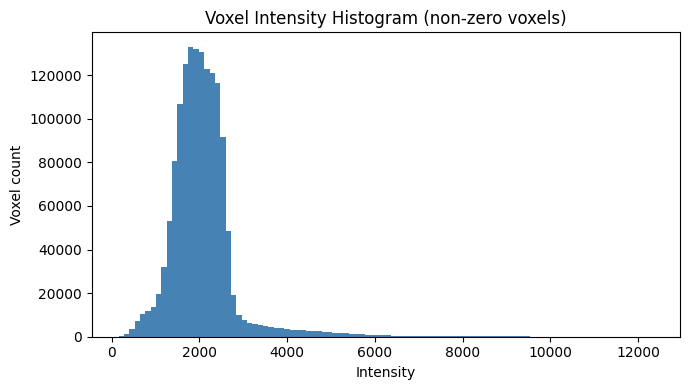

In [9]:
import matplotlib.pyplot as plt

def intensity_stats(data):
    flat = data[np.isfinite(data)]
    stats = {
        "min": float(np.min(flat)),
        "max": float(np.max(flat)),
        "mean": float(np.mean(flat)),
        "median": float(np.median(flat)),
        "std": float(np.std(flat)),
        "p01": float(np.percentile(flat, 1)),
        "p99": float(np.percentile(flat, 99)),
    }
    return stats

if mri_data is not None:
    stats = intensity_stats(mri_data)
    print("Intensity Statistics")
    print("-" * 40)
    for k, v in stats.items():
        print(f"{k:>8}: {v:.4f}")

    plt.figure(figsize=(7, 4))
    plt.hist(mri_data[mri_data > 0].ravel(), bins=100, color="steelblue")
    plt.title("Voxel Intensity Histogram (non-zero voxels)")
    plt.xlabel("Intensity")
    plt.ylabel("Voxel count")
    plt.tight_layout()
    plt.show()
else:
    print("No MRI data loaded — skipping intensity analysis.")


## 9. 2D Slice Visualization

We display the middle axial, sagittal, and coronal slices of the loaded volume, using the array-axis
mapping determined in the Orientation section above (not a hard-coded axis order).


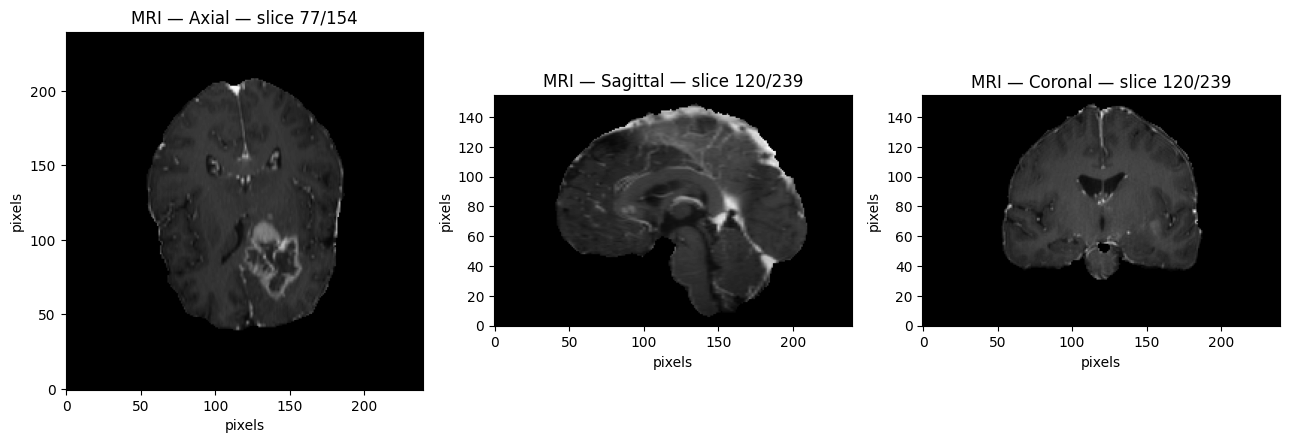

In [10]:
def visualize_slices(data, axcodes, indices=None, title_prefix=""):
    '''Display axial, sagittal, coronal slices from a 3D array.
    `axcodes` maps array axis index -> anatomical code, as returned by describe_orientation().
    `indices` optionally specifies which slice index to show per axis; defaults to the middle slice.
    '''
    plane_for_code = {"L": "Sagittal", "R": "Sagittal", "A": "Coronal", "P": "Coronal",
                       "S": "Axial", "I": "Axial"}

    axis_to_plane = {i: plane_for_code.get(c, "Unknown") for i, c in enumerate(axcodes)}
    plane_to_axis = {v: k for k, v in axis_to_plane.items()}  # last one wins if duplicates

    if indices is None:
        indices = {ax: data.shape[ax] // 2 for ax in range(data.ndim)}

    fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
    for ax_plot, plane in zip(axes, ["Axial", "Sagittal", "Coronal"]):
        if plane not in plane_to_axis:
            ax_plot.set_title(f"{plane} (unavailable)")
            ax_plot.axis("off")
            continue
        array_axis = plane_to_axis[plane]
        idx = indices[array_axis]
        sl = np.take(data, idx, axis=array_axis)
        ax_plot.imshow(sl.T, cmap="gray", origin="lower")
        ax_plot.set_title(f"{title_prefix}{plane} — slice {idx}/{data.shape[array_axis]-1}")
        ax_plot.set_xlabel("pixels")
        ax_plot.set_ylabel("pixels")
    plt.tight_layout()
    plt.show()

if mri_data is not None and mri_axcodes is not None:
    visualize_slices(mri_data, mri_axcodes, title_prefix="MRI — ")
else:
    print("No MRI data/orientation available — skipping slice visualization.")


## 10. Slice Viewer

If `ipywidgets` is available, this creates interactive sliders for axial, sagittal, and coronal
slice indices. Otherwise, it falls back to a simple non-interactive grid of a few slices per plane.


In [11]:
def interactive_slice_viewer(data, axcodes):
    try:
        import ipywidgets as widgets
        from IPython.display import display

        plane_for_code = {"L": "Sagittal", "R": "Sagittal", "A": "Coronal", "P": "Coronal",
                           "S": "Axial", "I": "Axial"}
        axis_to_plane = {i: plane_for_code.get(c, "Unknown") for i, c in enumerate(axcodes)}
        plane_to_axis = {v: k for k, v in axis_to_plane.items()}

        sliders = {}
        for plane, axis in plane_to_axis.items():
            sliders[plane] = widgets.IntSlider(
                min=0, max=data.shape[axis] - 1, value=data.shape[axis] // 2,
                description=plane
            )

        def _update(**kwargs):
            indices = {plane_to_axis[plane]: val for plane, val in kwargs.items()}
            visualize_slices(data, axcodes, indices=indices)

        out = widgets.interactive(_update, **sliders)
        display(out)
        return out
    except ImportError:
        print("ipywidgets not available — using non-interactive fallback (fixed slice grid).")
        _fallback_slice_grid(data, axcodes)


def _fallback_slice_grid(data, axcodes, n_slices=3):
    plane_for_code = {"L": "Sagittal", "R": "Sagittal", "A": "Coronal", "P": "Coronal",
                       "S": "Axial", "I": "Axial"}
    axis_to_plane = {i: plane_for_code.get(c, "Unknown") for i, c in enumerate(axcodes)}
    plane_to_axis = {v: k for k, v in axis_to_plane.items()}

    fig, axes = plt.subplots(len(plane_to_axis), n_slices, figsize=(4 * n_slices, 4 * len(plane_to_axis)))
    if len(plane_to_axis) == 1:
        axes = np.array([axes])

    for row, (plane, axis) in enumerate(plane_to_axis.items()):
        size = data.shape[axis]
        positions = np.linspace(size * 0.25, size * 0.75, n_slices).astype(int)
        for col, idx in enumerate(positions):
            sl = np.take(data, idx, axis=axis)
            ax_plot = axes[row, col] if n_slices > 1 else axes[row]
            ax_plot.imshow(sl.T, cmap="gray", origin="lower")
            ax_plot.set_title(f"{plane} — slice {idx}")
            ax_plot.axis("off")
    plt.tight_layout()
    plt.show()

if mri_data is not None and mri_axcodes is not None:
    interactive_slice_viewer(mri_data, mri_axcodes)
else:
    print("No MRI data/orientation available — skipping slice viewer.")


interactive(children=(IntSlider(value=120, description='Sagittal', max=239), IntSlider(value=120, description=…

## 11. Segmentation Mask Detection

We look for a ground-truth segmentation mask near the selected MRI (same folder, filename containing
`seg`, `mask`, `label`, or `gt`). If found, we overlay it on the MRI; if not, we clearly say so —
we never fabricate a mask.


Segmentation mask found: C:\Users\admin\Desktop\Med_Twin\Dataset\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00000-000\BraTS-GLI-00000-000-seg.nii.gz
Mask shape: (240, 240, 155)


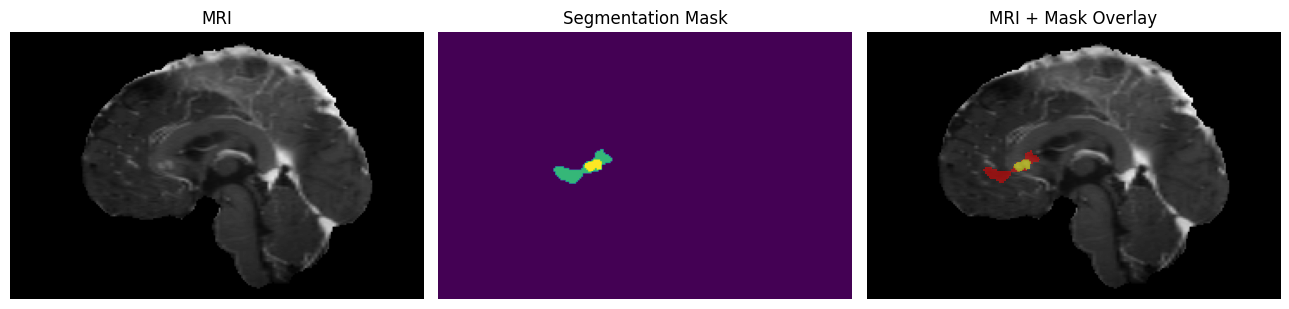

In [12]:
seg_img = None
seg_data = None

def find_segmentation_mask(mri_path: Path):
    '''Look for a plausible segmentation mask file next to the given MRI file.'''
    if mri_path is None or not mri_path.exists():
        return None
    candidates = [
        p for p in mri_path.parent.glob("*")
        if p.is_file() and _has_ext(p, NIFTI_EXTS)
        and any(hint in p.name.lower() for hint in MASK_HINTS)
    ]
    return sorted(candidates)[0] if candidates else None

mask_path = None
if selected_mri_format == "NIfTI" and selected_mri_path is not None:
    mask_path = find_segmentation_mask(selected_mri_path)

if mask_path is not None and nib is not None:
    seg_img = nib.load(str(mask_path))
    seg_data = seg_img.get_fdata()
    print(f"Segmentation mask found: {mask_path}")
    print(f"Mask shape: {seg_data.shape}")

    if mri_data is not None and seg_data.shape == mri_data.shape:
        mid_axis = 0  # default to array axis 0 for a quick overlay view
        idx = mri_data.shape[mid_axis] // 2
        mri_slice = np.take(mri_data, idx, axis=mid_axis)
        seg_slice = np.take(seg_data, idx, axis=mid_axis)

        fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
        axes[0].imshow(mri_slice.T, cmap="gray", origin="lower")
        axes[0].set_title("MRI")
        axes[0].axis("off")

        axes[1].imshow(seg_slice.T, cmap="viridis", origin="lower")
        axes[1].set_title("Segmentation Mask")
        axes[1].axis("off")

        axes[2].imshow(mri_slice.T, cmap="gray", origin="lower")
        masked = np.ma.masked_where(seg_slice.T == 0, seg_slice.T)
        axes[2].imshow(masked, cmap="autumn", alpha=0.5, origin="lower")
        axes[2].set_title("MRI + Mask Overlay")
        axes[2].axis("off")

        plt.tight_layout()
        plt.show()
    else:
        print("Mask shape does not match MRI shape (or MRI not loaded) — skipping overlay display.")
else:
    print("No ground-truth segmentation mask detected.")
    print("Segmentation will be implemented in Phase 2.")


## 12. Segmentation Label Inspection

If a mask was loaded, we report the unique integer labels present and their voxel counts. We do
**not** guess what each label anatomically represents unless the dataset's own documentation
confirms it — the "Meaning" column is left blank unless you fill it in from the dataset's official
documentation (e.g. the BraTS label convention).


In [13]:
import pandas as pd

def inspect_labels(seg_data):
    labels, counts = np.unique(seg_data.astype(int), return_counts=True)
    df = pd.DataFrame({
        "Label": labels,
        "Meaning": ["(fill in from dataset documentation)"] * len(labels),
        "Voxel count": counts,
    })
    return df

if seg_data is not None:
    label_table = inspect_labels(seg_data)
    print("Unique segmentation labels found:")
    display(label_table)
else:
    print("No segmentation mask available — skipping label inspection.")
    label_table = None


Unique segmentation labels found:


,Label,Meaning,Voxel count
0,0,(fill in from dataset documentation),8870695
1,1,(fill in from dataset documentation),11738
2,2,(fill in from dataset documentation),12836
3,3,(fill in from dataset documentation),32731


## 13. Basic Voxel-Volume Calculation

This is an **exploratory** calculation only, using the voxel spacing read from the NIfTI affine
matrix. If a segmentation mask is available, we estimate its volume from non-zero voxel counts.

> **Important:** this is a *preliminary voxel-based volume estimate from the dataset annotation* —
> it is **not** a clinically validated tumor volume measurement.


In [14]:
def calculate_voxel_volume(spacing):
    '''Return the volume of a single voxel in mm^3 given (sx, sy, sz) spacing in mm.'''
    sx, sy, sz = spacing
    return float(sx * sy * sz)

voxel_volume_mm3 = None
voxel_volume_cm3 = None
mask_volume_mm3 = None
mask_volume_cm3 = None
mask_voxel_count = None

if mri_voxel_spacing is not None:
    voxel_volume_mm3 = calculate_voxel_volume(mri_voxel_spacing)
    voxel_volume_cm3 = voxel_volume_mm3 / 1000.0

    print("Voxel Volume")
    print("-" * 40)
    print(f"Spacing (x,y,z): {tuple(round(s,4) for s in mri_voxel_spacing)} mm")
    print(f"Voxel volume:    {voxel_volume_mm3:.6f} mm^3  ({voxel_volume_cm3:.9f} cm^3)")

    if seg_data is not None:
        mask_voxel_count = int(np.count_nonzero(seg_data))
        mask_volume_mm3 = mask_voxel_count * voxel_volume_mm3
        mask_volume_cm3 = mask_volume_mm3 / 1000.0

        print(f"\nMask non-zero voxels: {mask_voxel_count:,}")
        print(f"Preliminary voxel-based volume estimate from the dataset annotation:")
        print(f"  {mask_volume_mm3:.2f} mm^3  ({mask_volume_cm3:.4f} cm^3)")
        print("\nThis is NOT a clinically validated tumor volume.")
else:
    print("No voxel spacing available — skipping volume calculation.")


Voxel Volume
----------------------------------------
Spacing (x,y,z): (1.0, 1.0, 1.0) mm
Voxel volume:    1.000000 mm^3  (0.001000000 cm^3)

Mask non-zero voxels: 57,305
Preliminary voxel-based volume estimate from the dataset annotation:
  57305.00 mm^3  (57.3050 cm^3)

This is NOT a clinically validated tumor volume.


## 14. MRI Quality / Validation Checks

Basic automated sanity checks on the loaded volume (and mask, if present). These are structural
validations only — we do not invent any medical quality score.


In [15]:
def validate_volume(data, spacing, seg=None):
    checks = {}

    checks["3D volume"] = data.ndim == 3
    checks["No NaN values"] = not np.isnan(data).any()
    checks["No infinite values"] = not np.isinf(data).any()
    checks["Not empty (has non-zero voxels)"] = np.count_nonzero(data) > 0
    checks["Valid voxel spacing (>0)"] = spacing is not None and all(s > 0 for s in spacing)
    checks["Reasonable dimensions (>= 10 per axis)"] = all(s >= 10 for s in data.shape)

    if seg is not None:
        checks["Mask shape matches MRI"] = seg.shape == data.shape
        checks["Mask contains foreground"] = np.count_nonzero(seg) > 0
    else:
        checks["Mask shape matches MRI"] = None
        checks["Mask contains foreground"] = None

    return checks

if mri_data is not None:
    validation = validate_volume(mri_data, mri_voxel_spacing, seg_data)

    print("MRI Validation")
    print("-" * 40)
    for name, result in validation.items():
        if result is None:
            status = "N/A (no mask)"
        else:
            status = "PASS" if result else "FAIL"
        print(f"{name:<38}: {status}")
else:
    print("No MRI data loaded — skipping validation.")
    validation = None


MRI Validation
----------------------------------------
3D volume                             : PASS
No NaN values                         : PASS
No infinite values                    : PASS
Not empty (has non-zero voxels)       : PASS
Valid voxel spacing (>0)              : PASS
Reasonable dimensions (>= 10 per axis): PASS
Mask shape matches MRI                : PASS
Mask contains foreground              : PASS


## 15. Save Exploration Report

We collect everything we learned into a single summary dictionary and optionally save it as JSON in
`OUTPUT_DIR` for reference when starting Phase 2.


In [16]:
import json
import datetime

dataset_summary = {
    "file": str(selected_mri_path) if selected_mri_path else None,
    "format": selected_mri_format,
    "shape": list(mri_data.shape) if mri_data is not None else None,
    "voxel_spacing_mm": list(mri_voxel_spacing) if mri_voxel_spacing is not None else None,
    "dtype": str(mri_img.get_data_dtype()) if mri_img is not None else None,
    "min_intensity": float(np.nanmin(mri_data)) if mri_data is not None else None,
    "max_intensity": float(np.nanmax(mri_data)) if mri_data is not None else None,
    "mean_intensity": float(np.nanmean(mri_data)) if mri_data is not None else None,
    "median_intensity": float(np.nanmedian(mri_data)) if mri_data is not None else None,
    "mask_available": seg_data is not None,
    "mask_path": str(mask_path) if mask_path else None,
    "mask_voxel_count": mask_voxel_count,
    "voxel_volume_mm3": voxel_volume_mm3,
    "mask_volume_mm3_preliminary": mask_volume_mm3,
    "generated_at": datetime.datetime.now().isoformat(timespec="seconds"),
}

print("Exploration Report")
print("-" * 40)
for k, v in dataset_summary.items():
    print(f"{k:<30}: {v}")

report_path = OUTPUT_DIR / "phase1_exploration_report.json"
try:
    with open(report_path, "w") as f:
        json.dump(dataset_summary, f, indent=2, default=str)
    print(f"\nSaved report to: {report_path}")
except Exception as e:
    print(f"\nCould not save report: {e}")


Exploration Report
----------------------------------------
file                          : C:\Users\admin\Desktop\Med_Twin\Dataset\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00000-000\BraTS-GLI-00000-000-t1c.nii.gz
format                        : NIfTI
shape                         : [240, 240, 155]
voxel_spacing_mm              : [1.0, 1.0, 1.0]
dtype                         : int16
min_intensity                 : 0.0
max_intensity                 : 12343.0
mean_intensity                : 345.5059033378136
median_intensity              : 0.0
mask_available                : True
mask_path                     : C:\Users\admin\Desktop\Med_Twin\Dataset\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00000-000\BraTS-GLI-00000-000-seg.nii.gz
mask_voxel_count              : 57305
voxel_volume_mm3              : 1.0
mask_volume_mm3_preliminary   : 57305.0
generated_at                  : 2026-08-20T18:30:07

Saved report to: C:\Users\admin\Desktop\Med_Twin\outputs\p

## 16. Final Notebook Summary

### What we completed
- Checked the Python environment and reported available/missing packages
- Configured dataset and output paths via `pathlib`
- Recursively scanned the dataset and summarized file types
- Selected and loaded a real MRI volume (NIfTI, and DICOM if present) — no fabricated data
- Inspected volume metadata: shape, dtype, affine, voxel spacing
- Determined true anatomical orientation from the affine (not assumed axis order)
- Computed raw intensity statistics and a histogram (no aggressive normalization)
- Visualized axial, sagittal, and coronal slices, plus an interactive/fallback slice viewer
- Detected a ground-truth segmentation mask if present, and overlaid it on the MRI
- Inspected unique segmentation labels and voxel counts (without guessing their meaning)
- Computed a preliminary, clearly-labeled voxel-based volume estimate
- Ran structural validation checks on the volume and mask
- Saved a JSON exploration report to `outputs/`

### What we have NOT done
- No deep-learning training
- No disease classifier
- No automatic segmentation
- No 3D reconstruction
- No clinical diagnosis
- No final digital twin
- No AI-generated clinical report


## 17. Next Phase

```
PHASE 1 COMPLETE

The MRI/CT dataset has been successfully inspected.

Next Phase:
Brain Segmentation

Recommended next step:
Train/test a 3D brain segmentation model using the validated volumetric data.
```

**After I run this notebook successfully, I will give you the next prompt for Phase 2 — Brain Segmentation.**
